# Figure S6B — V2 prediction time vs batch size

Time for metapredict V2 to predict the human reference proteome (20,652 sequences) as a function of batch size (sequences per forward pass), one line per machine and device (CPU black, Apple MPS red, CUDA blue). Open squares mark the batch size metapredict 3.1.0 uses by default on that device (256 on CPU and CUDA, 512 on MPS). Batch size changes speed and memory only: predicted scores agree to ~1e-6 across batch sizes (`max_abs_diff_vs_min_batch` in the results). Batch sizes that ran out of GPU memory have no point. The legend is in Figure S6A.

**How it is made.** Every TSV in `data/benchmarks/batch_size/`, written by `benchmarks/batch_size/run_batch_size_sweep.py` with metapredict 3.1.0 (warmup excluded from the timing, device synchronised before the clock stops). Repeat measurements are summarised by their median.

**Output:** `figures/figure_S06B.pdf`

In [1]:
import matplotlib.pyplot as plt

from figtools import apply_style, save_panel
from perf_plots import load_results, plot_batch_size_panel

apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
rows = load_results('batch_size')

batch_size: 142 rows from 7 files; metapredict (version, commit): [('3.1.0+6.ga1b28a7.dirty', '7dcf52c+dirty'), ('3.1.0+7.g7dcf52c.dirty', '7dcf52c+dirty')]


  ('M3 Max\nCPU', 'cpu', 32): 3 repeat runs, using the median
  ('M3 Max\nCPU', 'cpu', 64): 3 repeat runs, using the median
  ('M3 Max\nCPU', 'cpu', 128): 3 repeat runs, using the median
  ('M3 Max\nCPU', 'cpu', 256): 3 repeat runs, using the median
  ('M3 Max\nCPU', 'cpu', 512): 3 repeat runs, using the median
  ('M3 Max\nCPU', 'cpu', 1024): 3 repeat runs, using the median
  ('Xeon Silver 4210R\nCPU', 'cpu', 32): 3 repeat runs, using the median
  ('Xeon Silver 4210R\nCPU', 'cpu', 64): 3 repeat runs, using the median
  ('Xeon Silver 4210R\nCPU', 'cpu', 128): 3 repeat runs, using the median
  ('Xeon Silver 4210R\nCPU', 'cpu', 256): 3 repeat runs, using the median
  ('Xeon Silver 4210R\nCPU', 'cpu', 512): 3 repeat runs, using the median
  ('Xeon Silver 4210R\nCPU', 'cpu', 1024): 3 repeat runs, using the median
Wrote figures/figure_S06B.pdf


PosixPath('figures/figure_S06B.pdf')

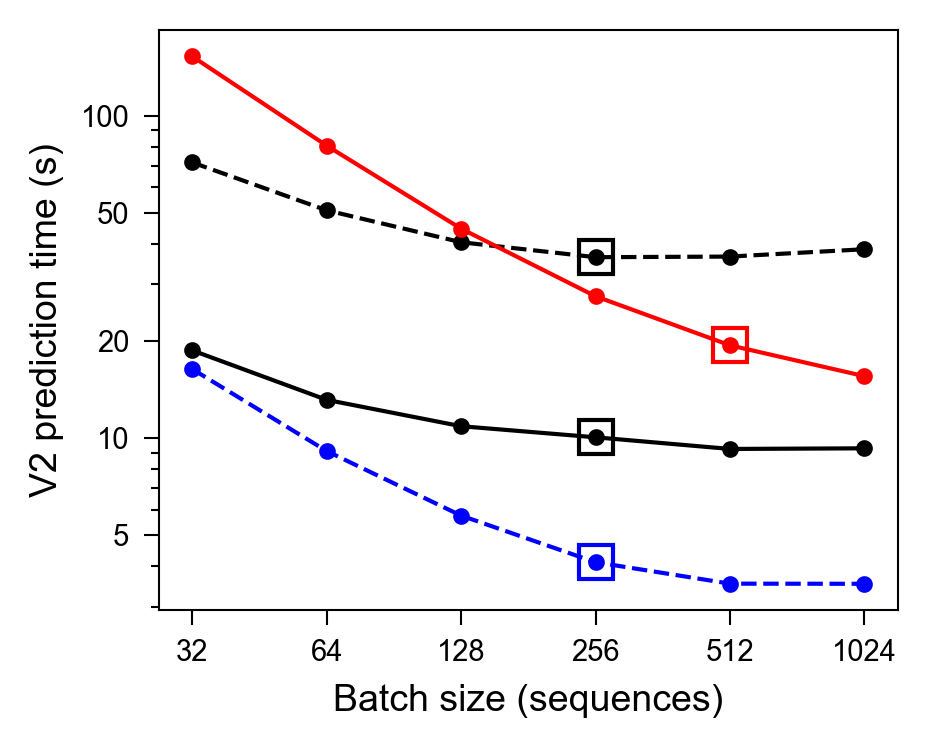

In [3]:
fig, ax = plt.subplots(figsize=(3.2, 2.6), dpi=150)
plot_batch_size_panel(ax, rows, 'V2', show_legend=False)
plt.tight_layout()
save_panel(fig, 'figure_S06B')